# A minimal VAE for Irish wind maps

This notebook trains a **variational autoencoder (VAE)** on 40 years of daily-maximum wind maps over
Ireland (ERA5, 32 × 32 grid, 1985–2024). It learns to compress each day's map into a few numbers and
rebuild it, and it can generate new, realistic-looking maps.

**How to use it**
1. On Colab: *Runtime → Change runtime type → T4 GPU*, then *Runtime → Run all*. Training takes about a minute.
2. To experiment: change the numbers in **Section 1 (settings)**, give the run a new `RUN_NAME`, and *Run all* again.
3. Every run is saved (Section 5), so you can compare runs later (Section 10), even after closing Colab.
4. Edit and break any cell you like. To get a fresh copy, reopen the notebook from the Colab link.

Data: *Generated using Copernicus Climate Change Service information [2026]* (ERA5 reanalysis).

## 0 · Setup: get the code and data, find the GPU

In [1]:
import copy, subprocess, sys, time
from datetime import datetime
from pathlib import Path

REPO_URL = "https://github.com/jfk1327/ai_weather_pres3.git"
DATA_FILE = Path("data") / "era5_ireland_wind_daily_max.nc"
IN_COLAB = "google.colab" in sys.modules

# Look for the data next to this notebook (running locally) or in an earlier clone (Colab re-run)
candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / "ai_weather"]
ROOT = next((p for p in candidates if (p / DATA_FILE).exists()), None)
if ROOT is None:                      # first run on Colab: download the repo, which includes the data
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "ai_weather"], check=True)
    ROOT = Path.cwd() / "ai_weather"
DATA_PATH = ROOT / DATA_FILE

try:
    import netCDF4                    # needed by xarray to read .nc files
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "netCDF4"], check=True)
print("data file:", DATA_PATH)

data file: /home/james/project/AI_weather/data/era5_ireland_wind_daily_max.nc


In [2]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    print("Using GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU found - training will be slower. On Colab: Runtime -> Change runtime type -> T4 GPU")

Using GPU: NVIDIA GeForce RTX 5060 Laptop GPU


## 1 · Settings: change these, give the run a new name, and re-run everything

| Setting | What it controls |
|---|---|
| `RUN_NAME` | a short name for this run that says what you changed, e.g. `"beta10"` or `"latent4"` |
| `VARIABLE` | `"gust"` (daily max gust) or `"speed"` (daily max 10 m wind speed) |
| `LATENT_DIM` | how many numbers the encoder squeezes each 1024-pixel map into |
| `BETA` | weight on the KL term: higher → smoother, more "average" latent space; lower → sharper reconstructions |
| `EPOCHS` | passes over the training data |
| `BATCH_SIZE`, `LR` | maps per gradient step, and the Adam learning rate |
| `BASE_CHANNELS` | width of the network (number of filters in the first conv layer) |
| `SAVE_TO_DRIVE` | on Colab, save runs to your Google Drive so they survive restarts |
| `EVALUATE_ON_TEST` | leave `False` while experimenting; turn on **once**, at the end (Section 11) |

In [3]:
RUN_NAME = "baseline"
VARIABLE = "gust"
LATENT_DIM = 16
BETA = 1.0
EPOCHS = 30
BATCH_SIZE = 128
LR = 1e-3
BASE_CHANNELS = 32
SEED = 0
SAVE_TO_DRIVE = True
EVALUATE_ON_TEST = False   # turn on once, at the end, for your chosen settings

## 2 · Data

Each sample is **one day**: a 32 × 32 map of the strongest wind at each grid cell (cells ≈ 28 km N–S × 16 km E–W).

The years are split into three groups with different jobs:

| Split | Years | Job |
|---|---|---|
| **train** | 1985–2014 | the model learns its weights from these |
| **validation** | 2015–2019 | *you* use these to compare runs and choose settings |
| **test** | 2020–2024 | kept unseen, and used **once** at the end to report how good the final model is |

Why keep test separate? If you look at test results while choosing settings, you start picking settings
that happen to suit those years, and the final number becomes too optimistic. The split is **by year**,
not random, because neighbouring days look alike: a random split would let the model "see" validation
days during training.

**Normalising:** one mean and one standard deviation, computed **from the training years only**, so the
network sees numbers around 0 instead of 0–57 m/s. `denormalise` turns model output back into m/s.

In [4]:
torch.manual_seed(SEED)
ds = xr.open_dataset(DATA_PATH)
maps = ds[VARIABLE]                                            # dims: (time, latitude, longitude)

def years(first, last):
    """All maps from `first` to `last` (inclusive) as a float32 tensor of shape (days, 32, 32), in m/s."""
    return torch.from_numpy(maps.sel(time=slice(str(first), str(last))).values).float()

train_raw, val_raw, test_raw = years(1985, 2014), years(2015, 2019), years(2020, 2024)
val_dates = maps.sel(time=slice("2015", "2019")).time.values
print("days  train / val / test:", len(train_raw), len(val_raw), len(test_raw))

MEAN, STD = train_raw.mean(), train_raw.std()                  # training years only!
def normalise(x):   return (x - MEAN) / STD
def denormalise(x): return x * STD + MEAN
print(f"normalisation: mean {MEAN:.2f} m/s, std {STD:.2f} m/s")

def make_loader(raw, shuffle):
    x = normalise(raw).unsqueeze(1)                            # (days, 1, 32, 32): Conv2d wants a channel axis
    return DataLoader(TensorDataset(x), batch_size=BATCH_SIZE, shuffle=shuffle)

train_loader = make_loader(train_raw, shuffle=True)            # shuffle so each batch mixes seasons and years
val_loader = make_loader(val_raw, shuffle=False)               # order doesn't matter for an average
print("one batch:", next(iter(train_loader))[0].shape)

days  train / val / test: 10957 1826 1827
normalisation: mean 14.76 m/s, std 5.79 m/s
one batch: torch.Size([128, 1, 32, 32])


## 3 · The model

```
map (1, 32, 32) ─ encoder ─► μ, log σ²  (LATENT_DIM numbers each)
                                │  z = μ + σ · ε,  ε ~ N(0, 1)     ← "reparameterisation trick"
                                ▼
                z (LATENT_DIM) ─ decoder ─► reconstructed map (1, 32, 32)
```
Each `Conv2d(kernel 4, stride 2, padding 1)` halves the map size: 32 → 16 → 8 → 4.
Each `ConvTranspose2d` with the same settings doubles it back: 4 → 8 → 16 → 32.

In [5]:
class VAE(nn.Module):
    def __init__(self, latent_dim, c):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, c, 4, stride=2, padding=1), nn.ReLU(),          # (1, 32, 32)  -> (c, 16, 16)
            nn.Conv2d(c, 2 * c, 4, stride=2, padding=1), nn.ReLU(),      # -> (2c, 8, 8)
            nn.Conv2d(2 * c, 4 * c, 4, stride=2, padding=1), nn.ReLU(),  # -> (4c, 4, 4)
            nn.Flatten(),                                                # -> 4c * 16 numbers
        )
        n = 4 * c * 4 * 4
        self.to_mu = nn.Linear(n, latent_dim)
        self.to_logvar = nn.Linear(n, latent_dim)                        # log of the variance: can be any real number
        self.from_z = nn.Linear(latent_dim, n)
        self.decoder = nn.Sequential(
            nn.Unflatten(1, (4 * c, 4, 4)), nn.ReLU(),                   # -> (4c, 4, 4)
            nn.ConvTranspose2d(4 * c, 2 * c, 4, stride=2, padding=1), nn.ReLU(),  # -> (2c, 8, 8)
            nn.ConvTranspose2d(2 * c, c, 4, stride=2, padding=1), nn.ReLU(),      # -> (c, 16, 16)
            nn.ConvTranspose2d(c, 1, 4, stride=2, padding=1),            # -> (1, 32, 32); no activation: data is normalised
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.to_mu(h), self.to_logvar(h)

    def decode(self, z):
        return self.decoder(self.from_z(z))

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)          # sample z, but keep gradients flowing
        return self.decode(z), mu, logvar

model = VAE(LATENT_DIM, BASE_CHANNELS).to(device)
N_PARAMS = sum(p.numel() for p in model.parameters())
print(f"parameters: {N_PARAMS:,}")

# shape check: 2 fake maps in, 2 maps out
x_hat, mu, logvar = model(torch.zeros(2, 1, 32, 32, device=device))
print("output:", tuple(x_hat.shape), "| mu:", tuple(mu.shape))

parameters: 429,409


output: (2, 1, 32, 32) | mu: (2, 16)


## 4 · The loss: two parts pulling in different directions

**loss = reconstruction + β · KL**

- **Reconstruction**: how different the rebuilt map is from the real one (squared error, summed over the
  1024 pixels). On its own, this would make the model a plain compressor.
- **KL**: how far each map's code is from a standard bell curve N(0, 1). It pulls the codes of all days
  into one smooth cloud. That's what lets the model **generate** new maps (Section 9): any random point
  in the cloud decodes to a sensible map.

The two compete. Packing more detail into the code helps reconstruction but costs KL. **β sets the
exchange rate.**

**Reading the numbers**
- Reconstruction is in normalised units, which are hard to picture, so the notebook also turns it into an
  **average error in m/s per pixel**: `error_ms = sqrt(recon / 1024) × STD`.
- **Don't compare the total loss between runs with different β.** β changes what "total" means.
  Compare the error in m/s and the KL separately.

In [6]:
def vae_loss(x, x_hat, mu, logvar, beta):
    n = x.shape[0]
    recon = F.mse_loss(x_hat, x, reduction="sum") / n
    kl = -0.5 * torch.sum(1 + logvar - mu ** 2 - logvar.exp()) / n   # closed form for two Gaussians
    return recon + beta * kl, recon, kl

def error_ms(recon):
    """Reconstruction loss -> average (root-mean-square) error per pixel in m/s."""
    return float(np.sqrt(float(recon) / (32 * 32)) * float(STD))

## 5 · Saving runs, so you know what you've tried

Every run saves into one folder (your Google Drive on Colab, or `runs/` on a laptop):

| File | What's in it |
|---|---|
| `runs_log.csv` | **one row per run**: name, all settings, best validation error (m/s), KL, time. Your record for the presentation |
| `<RUN_NAME>_history.csv` | the loss for every epoch (used by Section 10 to compare runs) |
| `<RUN_NAME>_losses.png`, `<RUN_NAME>_reconstructions.png` | figures ready for slides |
| `<RUN_NAME>.pt` | the trained model's weights |

**Tips for keeping track**
- Change **one** setting per run, and name the run after it (`beta10`, `latent4`, `lr1e-4`).
- Before you run, write down what you *expect* to happen. Afterwards, check whether you were right.
- The notebook **stops** if `RUN_NAME` has already been used, so old results are never overwritten by accident.

In [7]:
if SAVE_TO_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")                                 # asks for permission the first time
    SAVE_DIR = Path("/content/drive/MyDrive/vae_runs")
else:
    SAVE_DIR = ROOT / "runs"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
LOG = SAVE_DIR / "runs_log.csv"
print("saving runs to:", SAVE_DIR)

if LOG.exists():
    print("\nRuns so far:")
    display(pd.read_csv(LOG)[["run", "variable", "latent_dim", "beta", "epochs", "lr", "batch_size",
                              "base_channels", "best_val_error_ms", "best_val_kl"]])
else:
    print("No runs yet.")

if (SAVE_DIR / f"{RUN_NAME}_history.csv").exists():
    raise ValueError(f"A run called '{RUN_NAME}' already exists in {SAVE_DIR}. "
                     "Give this run a new RUN_NAME in Section 1 (or delete the old files) and run again.")

saving runs to: /home/james/project/AI_weather/runs
No runs yet.


## 6 · Training

In [8]:
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

def run_epoch(loader, train):
    """One pass over `loader`. Returns the average [total, recon, kl] per map."""
    model.train(train)
    sums, count = torch.zeros(3), 0
    with torch.set_grad_enabled(train):                  # no gradients needed for validation
        for (x,) in loader:
            x = x.to(device)
            x_hat, mu, logvar = model(x)
            loss, recon, kl = vae_loss(x, x_hat, mu, logvar, BETA)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            sums += torch.tensor([loss.item(), recon.item(), kl.item()]) * len(x)
            count += len(x)
    return sums / count

rows, best_val, best_state, epoch_times = [], float("inf"), None, []
print("epoch | train: error m/s, KL | val: error m/s, KL | time")
for epoch in range(1, EPOCHS + 1):
    start = time.time()
    tr, va = run_epoch(train_loader, train=True), run_epoch(val_loader, train=False)
    epoch_times.append(time.time() - start)
    rows.append({"epoch": epoch,
                 "train_total": float(tr[0]), "train_recon": float(tr[1]), "train_kl": float(tr[2]),
                 "val_total": float(va[0]), "val_recon": float(va[1]), "val_kl": float(va[2]),
                 "train_error_ms": error_ms(tr[1]), "val_error_ms": error_ms(va[1])})
    if va[0] < best_val:                                  # keep the model that does best on validation years
        best_val, best_epoch, best_state = float(va[0]), epoch, copy.deepcopy(model.state_dict())
    print(f"{epoch:5d} | {error_ms(tr[1]):5.2f} m/s, KL {tr[2]:5.1f} | "
          f"{error_ms(va[1]):5.2f} m/s, KL {va[2]:5.1f} | {epoch_times[-1]:4.1f}s")

model.load_state_dict(best_state)
model.eval()
history = pd.DataFrame(rows)
best = history.loc[best_epoch - 1]
print(f"\nbest epoch {best_epoch}: on validation days the reconstruction is off by "
      f"≈ {best.val_error_ms:.2f} m/s per pixel on average (KL {best.val_kl:.1f})")

epoch | train: error m/s, KL | val: error m/s, KL | time


    1 |  3.44 m/s, KL  23.3 |  1.91 m/s, KL  25.0 |  1.3s


    2 |  1.64 m/s, KL  24.2 |  1.53 m/s, KL  24.3 |  0.6s


    3 |  1.40 m/s, KL  24.8 |  1.31 m/s, KL  25.5 |  0.7s


    4 |  1.30 m/s, KL  24.9 |  1.29 m/s, KL  25.5 |  0.6s


...

   26 |  0.97 m/s, KL  23.0 |  0.97 m/s, KL  23.8 |  0.6s


   27 |  0.97 m/s, KL  23.0 |  1.00 m/s, KL  22.6 |  0.6s


   28 |  0.97 m/s, KL  22.9 |  0.99 m/s, KL  23.0 |  0.7s


   29 |  0.97 m/s, KL  22.9 |  0.99 m/s, KL  22.6 |  0.7s


   30 |  0.96 m/s, KL  22.8 |  0.99 m/s, KL  23.2 |  0.6s

best epoch 29: on validation days the reconstruction is off by ≈ 0.99 m/s per pixel on average (KL 22.6)


In [9]:
# save this run: one log row + per-epoch history + model weights
history.to_csv(SAVE_DIR / f"{RUN_NAME}_history.csv", index=False)
torch.save(model.state_dict(), SAVE_DIR / f"{RUN_NAME}.pt")
row = {"run": RUN_NAME, "date": datetime.now().strftime("%Y-%m-%d %H:%M"), "variable": VARIABLE,
       "latent_dim": LATENT_DIM, "beta": BETA, "epochs": EPOCHS, "batch_size": BATCH_SIZE, "lr": LR,
       "base_channels": BASE_CHANNELS, "seed": SEED, "parameters": N_PARAMS, "best_epoch": best_epoch,
       "best_val_error_ms": round(best.val_error_ms, 3), "best_val_kl": round(best.val_kl, 2),
       "sec_per_epoch": round(float(np.mean(epoch_times)), 2), "test_error_ms": np.nan}
pd.DataFrame([row]).to_csv(LOG, mode="a", header=not LOG.exists(), index=False)
print(f"saved run '{RUN_NAME}' to {SAVE_DIR}")

saved run 'baseline' to /home/james/project/AI_weather/runs


## 7 · Loss curves

Train vs validation for this run. If validation stops improving while train keeps falling, the model is
starting to memorise the training years (**overfitting**).

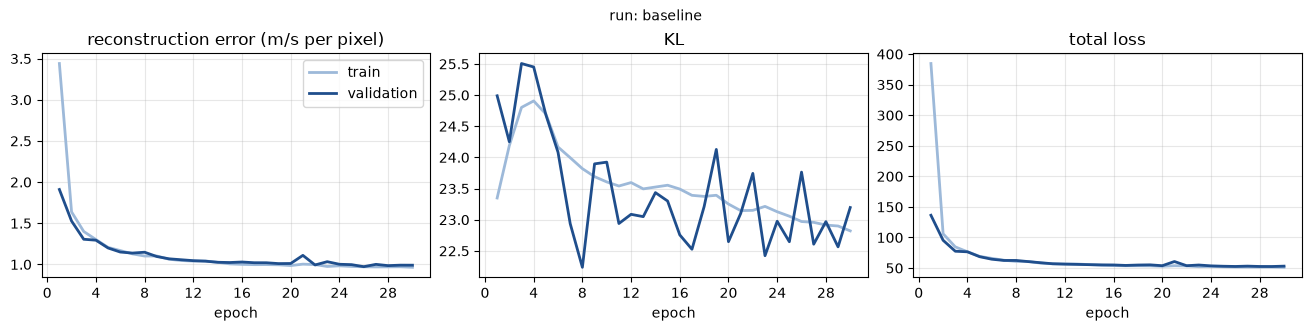

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), constrained_layout=True)
panels = [("error_ms", "reconstruction error (m/s per pixel)"), ("kl", "KL"), ("total", "total loss")]
for ax, (key, title) in zip(axes, panels):
    ax.plot(history.epoch, history[f"train_{key}"], lw=2, color="#9db9d9", label="train")
    ax.plot(history.epoch, history[f"val_{key}"], lw=2, color="#1f4e8c", label="validation")
    ax.set(title=title, xlabel="epoch"); ax.grid(alpha=0.3)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].legend()
fig.suptitle(f"run: {RUN_NAME}", fontsize=10)
fig.savefig(SAVE_DIR / f"{RUN_NAME}_losses.png", dpi=150, bbox_inches="tight");

## 8 · Reconstructions of validation days (2015–2019)

Top row: real day. Bottom row: the map rebuilt from its code μ. The first column is the windiest
validation day. Look at *where* the rebuilt maps differ: peaks, coasts, small features?

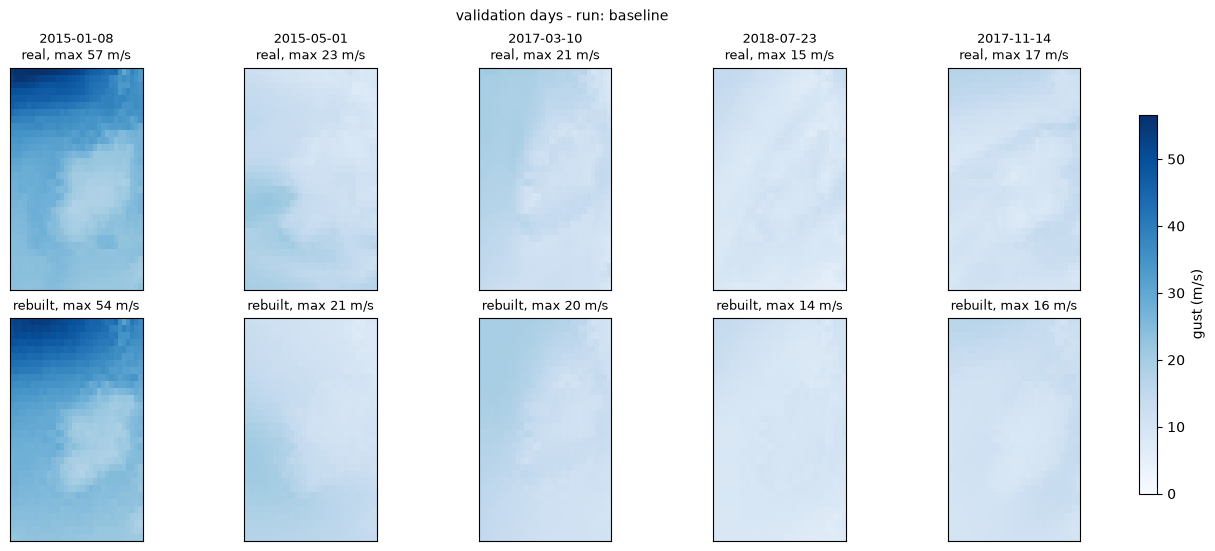

In [11]:
lon, lat = maps.longitude.values, maps.latitude.values
EXTENT = [lon.min() - 0.125, lon.max() + 0.125, lat.min() - 0.125, lat.max() + 0.125]
ASPECT = 1 / np.cos(np.deg2rad(53.5))     # cells are narrower E-W than N-S at Ireland's latitude

def show(ax, field, vmin, vmax, title=""):
    im = ax.imshow(field, origin="lower", extent=EXTENT, aspect=ASPECT, cmap="Blues", vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
    return im

@torch.no_grad()
def reconstruct(raw):
    x = normalise(raw).unsqueeze(1).to(device)
    mu, _ = model.encode(x)
    return denormalise(model.decode(mu).squeeze(1).cpu())

def plot_reconstructions(raw, dates, label):
    windiest = int(raw.amax(dim=(1, 2)).argmax())
    idx = [windiest] + torch.randint(len(raw), (4,), generator=torch.Generator().manual_seed(SEED)).tolist()
    real, recon = raw[idx], reconstruct(raw[idx])
    fig, axes = plt.subplots(2, len(idx), figsize=(2.6 * len(idx), 5.4), constrained_layout=True)
    vmax = float(real.max())
    for j, i in enumerate(idx):
        show(axes[0, j], real[j], 0, vmax, f"{str(dates[i])[:10]}\nreal, max {real[j].max():.0f} m/s")
        im = show(axes[1, j], recon[j], 0, vmax, f"rebuilt, max {recon[j].max():.0f} m/s")
    fig.colorbar(im, ax=axes, label=f"{VARIABLE} (m/s)", shrink=0.8)
    fig.suptitle(f"{label} - run: {RUN_NAME}", fontsize=10)
    return fig

fig = plot_reconstructions(val_raw, val_dates, "validation days")
fig.savefig(SAVE_DIR / f"{RUN_NAME}_reconstructions.png", dpi=150, bbox_inches="tight");

## 9 · New maps from the model

A VAE is **generative**: pick a random code z from the bell curve N(0, 1), decode it, and you get a
new map that never happened. That works only because the KL term (Section 4) packed the codes of real
days into that bell curve.

Top row: real validation days. Bottom rows: generated maps, on the same colour scale.
**Do the generated maps look like plausible weather? What's different from the real days?**

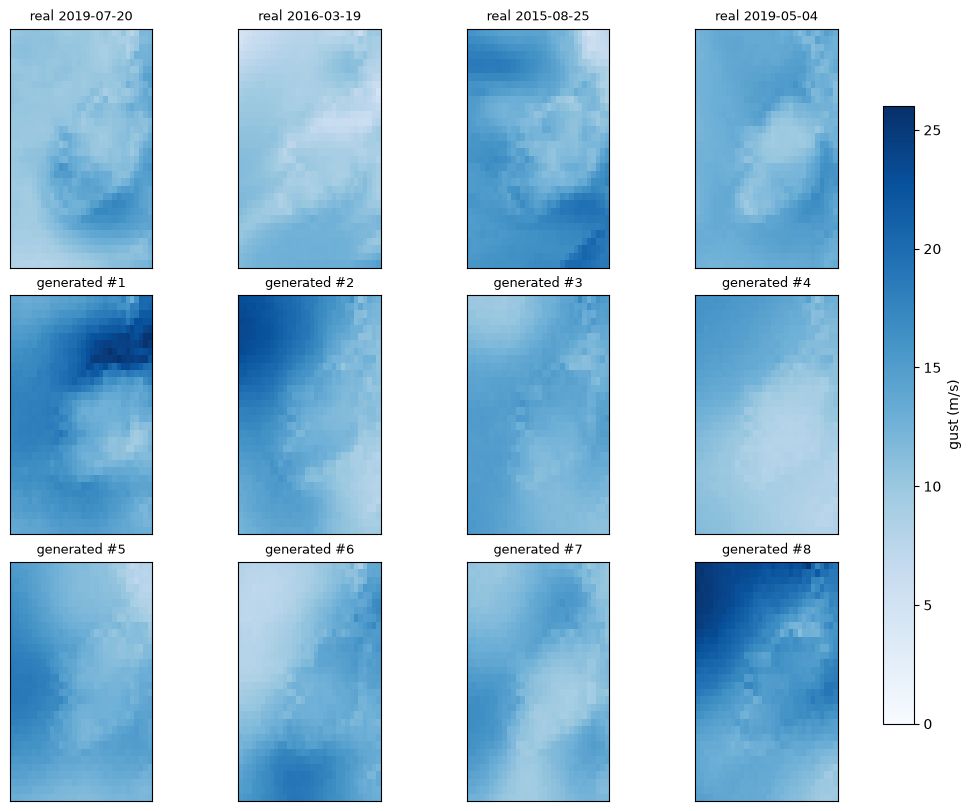

In [12]:
@torch.no_grad()
def generate(n):
    z = torch.randn(n, LATENT_DIM, device=device)        # random codes from N(0, 1)
    return denormalise(model.decode(z).squeeze(1).cpu())

torch.manual_seed(SEED)
new_maps = generate(8)
real_idx = torch.randint(len(val_raw), (4,), generator=torch.Generator().manual_seed(SEED + 1)).tolist()
vmax = max(float(new_maps.max()), float(val_raw[real_idx].max()))
fig, axes = plt.subplots(3, 4, figsize=(10.4, 8), constrained_layout=True)
for j, i in enumerate(real_idx):
    show(axes[0, j], val_raw[i], 0, vmax, f"real {str(val_dates[i])[:10]}")
for k in range(8):
    im = show(axes[1 + k // 4, k % 4], new_maps[k], 0, vmax, f"generated #{k + 1}")
fig.colorbar(im, ax=axes, label=f"{VARIABLE} (m/s)", shrink=0.8);

## 10 · Compare runs

Every run saved in your folder, on the **validation** years. Lower error = better reconstructions.
Remember: compare the error and the KL separately when runs have different β.

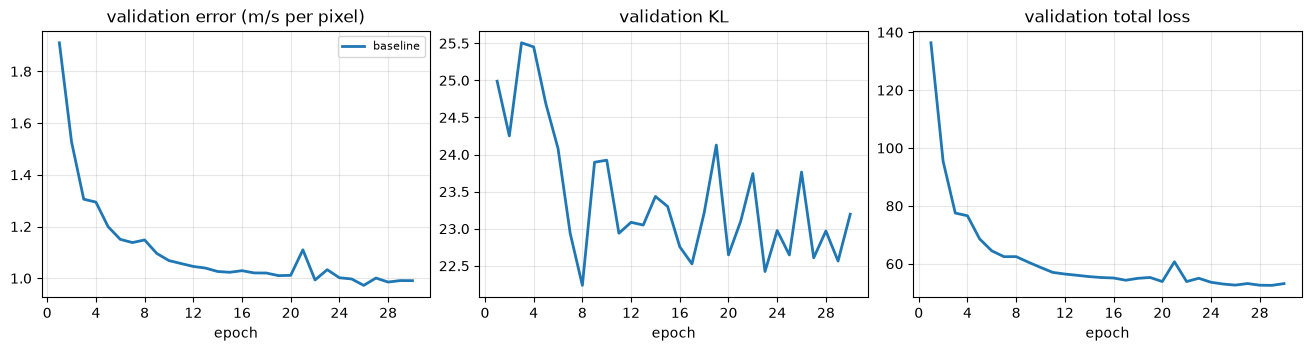

,run,variable,latent_dim,beta,epochs,lr,batch_size,base_channels,parameters,best_val_error_ms,best_val_kl,test_error_ms
0,baseline,gust,16,1.0,30,0.001,128,32,429409,0.991,22.56,NaN


In [13]:
log = pd.read_csv(LOG)
names = [r for r in log.run if (SAVE_DIR / f"{r}_history.csv").exists()][-10:]   # latest 10 runs
colours = plt.cm.tab10(np.arange(len(names)))                                   # fixed colour per run, in run order

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), constrained_layout=True)
for name, colour in zip(names, colours):
    h = pd.read_csv(SAVE_DIR / f"{name}_history.csv")
    for ax, key in zip(axes, ["val_error_ms", "val_kl", "val_total"]):
        ax.plot(h.epoch, h[key], lw=2, color=colour, label=name)
for ax, title in zip(axes, ["validation error (m/s per pixel)", "validation KL", "validation total loss"]):
    ax.set(title=title, xlabel="epoch"); ax.grid(alpha=0.3)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].legend(fontsize=8)
plt.show()

display(log.sort_values("best_val_error_ms")[["run", "variable", "latent_dim", "beta", "epochs", "lr",
        "batch_size", "base_channels", "parameters", "best_val_error_ms", "best_val_kl", "test_error_ms"]])

## 11 · Final check on unseen years (2020–2024)

Do this **once**, when you've finished experimenting:
1. In Section 1, put in the settings you chose, set `RUN_NAME = "final"` and `EVALUATE_ON_TEST = True`.
2. *Run all*. This trains your chosen model and reports its error on the test years, which nothing has
   looked at so far. That is the number to report.

If you then change settings because of the test result, test has become a second validation set and
its number is no longer a fair check.

In [14]:
if not EVALUATE_ON_TEST:
    print("Skipped: the test years stay unseen while you experiment. "
          "Set EVALUATE_ON_TEST = True in Section 1 for your final run.")
else:
    te = run_epoch(make_loader(test_raw, shuffle=False), train=False)
    test_err = error_ms(te[1])
    print(f"TEST years 2020-2024: reconstruction off by ≈ {test_err:.2f} m/s per pixel (KL {te[2]:.1f})")
    log = pd.read_csv(LOG)
    log.loc[log.run == RUN_NAME, "test_error_ms"] = round(test_err, 3)
    log.to_csv(LOG, index=False)
    test_dates = maps.sel(time=slice("2020", "2024")).time.values
    fig = plot_reconstructions(test_raw, test_dates, "TEST days (unseen)")
    fig.savefig(SAVE_DIR / f"{RUN_NAME}_test_reconstructions.png", dpi=150, bbox_inches="tight")

Skipped: the test years stay unseen while you experiment. Set EVALUATE_ON_TEST = True in Section 1 for your final run.


## 12 · Things to try: hyperparameter tuning

Change **one** setting at a time (plus a new `RUN_NAME`), run all, then compare in Section 10.
Judge runs on the **validation** error and KL, not the training loss.

| Try | Question to answer |
|---|---|
| `BETA = 0`, `0.1`, `10` | How do error and KL trade off? What do the generated maps (Section 9) look like at `BETA = 0`? |
| `LATENT_DIM = 2`, `4`, `64` | How small can the code be before the windiest day loses its peak? |
| `EPOCHS = 3` vs `60` | Is the model under-trained at 3? Does the train/validation gap grow at 60 (overfitting)? |
| `LR = 1e-4`, `1e-2` | Does training get slower, or unstable (jumpy curves)? |
| `BATCH_SIZE = 32`, `512` | How do speed per epoch and the final error change? |
| `BASE_CHANNELS = 8`, `64` | How much does error improve per extra parameter (see the `parameters` column)? |
| `VARIABLE = "speed"` | Is mean wind speed easier or harder to model than gusts? |
| Delete `beta * kl` from `vae_loss` | What happens to the KL curve and to the generated maps? Why does a VAE need the KL term? |

## 13 · Extensions: small research questions

Ideas that connect the model to real environmental questions. Each one is a few cells of new code.
While you're still choosing settings, use the **validation** years (2015–2019) for all of them.

**1. Deeper or shallower network** *(easy)*
*Does a bigger network rebuild storms better, or just cost more?*
1. In `VAE.__init__`, remove the third `Conv2d` and the first `ConvTranspose2d`. The bottleneck becomes
   `(2c, 8, 8)`, so change `n = 2 * c * 8 * 8` and `nn.Unflatten(1, (2 * c, 8, 8))`.
2. Or add a fourth pair (`4c → 8c`, 4 → 2), with `n = 8 * c * 2 * 2`.
3. Run the shape-check cell first. Then compare validation error against the `parameters` column.

**2. Where is the model worst? An error map** *(easy)*
*Is the model worse over land, at the coast, or at the edges of the box?*
1. `rebuilt = reconstruct(val_raw)`, then `err = ((rebuilt - val_raw) ** 2).mean(dim=0).sqrt()`
   gives a (32, 32) error per pixel in m/s.
2. Plot it with `show(...)` and a different colour map. Compare with the average wind map
   (`val_raw.mean(dim=0)`). Do errors follow the coastline? (Wind slows over rough land.)

**3. Put it on a real map** *(easy–medium)*
*Make the figures readable to anyone in the room.*
1. `pip install cartopy`, then `import cartopy.crs as ccrs`.
2. `ax = plt.axes(projection=ccrs.PlateCarree())`, then
   `ax.imshow(field, origin="lower", extent=EXTENT, transform=ccrs.PlateCarree(), cmap="Blues")`.
3. `ax.coastlines("50m")`. Show a real day and its reconstruction side by side.

**4. Real named storms** *(medium)*
*Does the model keep the shape and the peak of storms people remember?*
1. Validation-year storms (use these freely): Desmond 2015-12-05, Ophelia 2017-10-16, Emma 2018-03-01,
   Ali 2018-09-19, Lorenzo 2019-10-03. Check the dates against Met Éireann's storm lists.
2. `i = list(val_dates).index(np.datetime64("2017-10-16"))`, then `reconstruct(val_raw[i:i+1])`.
3. Compare real vs rebuilt: peak (m/s), where the peak is, and how big the windy area is.
4. **Only after your final test check (Section 11)**, try the test-year storms: Ciara 2020-02-09,
   Barra 2021-12-07, Eunice 2022-02-18, Agnes 2023-09-27, Isha 2024-01-21.

**5. Seasons** *(easy)*
*Are winter storm days harder to rebuild than calm summer days?*
1. Per-day error: `((reconstruct(val_raw) - val_raw) ** 2).mean(dim=(1, 2)).sqrt()`.
2. Group by month: `pd.Series(err.numpy(), index=pd.DatetimeIndex(val_dates)).groupby(lambda d: d.month).mean()`.
3. Plot as a bar chart, and relate it to the seasonal cycle of wind.

**6. Gust vs speed** *(easy)*
*Which is easier to model, and which matters for whom?* Damage and insurance work uses gusts; wind
energy uses sustained speed. Run the same settings with `VARIABLE = "speed"` and compare in Section 10.
Caveat: this is wind at 10 m, while turbine hubs are at around 100 m.

**7. A wind-energy angle** *(medium)*
*Would the model get turbine shut-downs right?* Turbines stop above a cut-out speed of about 25 m/s.
1. With `VARIABLE = "speed"`: `(val_raw > 25).float().mean(dim=0)` is the fraction of days above
   cut-out at each pixel.
2. Do the same for `reconstruct(val_raw)`. Does the model under-count high-wind days? Why might it?
   (Hint: what does squared error do to rare, sharp peaks?)
3. Caveats for the discussion: 10 m height, and daily maximum rather than hourly values.